# **Prediksi Stress Siswa menggunakan Random Forest**


In [64]:
import pandas as pd                   #Data Manipulation
import matplotlib.pyplot as plt       #Data Visualisation
import numpy as np                    #Mathematical Calculation
import seaborn as sns                 #Enchanced Data Visualisation
import sklearn                        #Machine Learning Algorithms
import warnings                       #Hide the Warnings
%matplotlib inline

In [65]:
url= 'https://raw.githubusercontent.com/shlokshukla200/ML-Random-Forest/refs/heads/main/StressLevelDataset.csv'

df=pd.read_csv(url)

In [66]:
df.head(10)

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1
5,20,13,1,21,3,3,1,4,3,2,...,1,2,5,2,5,1,4,4,5,2
6,4,26,0,6,1,2,4,1,1,4,...,4,5,1,4,1,3,2,2,1,0
7,17,3,1,22,4,3,1,5,3,1,...,1,1,3,2,4,1,4,4,5,2
8,13,22,1,12,3,1,2,4,3,3,...,3,3,3,2,3,3,3,2,2,1
9,6,8,0,27,4,3,1,2,0,5,...,2,2,2,1,5,1,5,3,4,1


In [67]:
# Anxiety Level ranges from 0 - 21
# Self Esteem ranges from 0-30
# Mental Health History ranges from 0-1
# Depression ranges from 0-27
# Headache ranges from 0-5
# BP ranges from 1-3
# Sleep Quality ranges from 0-5
# Breathing Problem ranges from 0-5
# Noise Level ranges from 0-5
# Living Conditions ranges from 0-5
# Safety ranges from 0-5
# Basic Needs ranges from 0-5
# Academics ranges from 0-5
# Study Load ranges from 0-5
# Teacher Student Relation ranges from 0-5
# Future Career Concerns ranges from 0-5
# Social Support ranges from 0-3
# Peer Pressure ranges from 0-5
# Extracurricular Activity ranges from 0-5
# Bullying ranges from 0-5
# Stress Level ranges from 0-2

# Analisis Data

In [68]:
df.describe()

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,...,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,11.063636,17.777273,0.492727,12.555455,2.508182,2.181818,2.660000,2.753636,2.649091,2.518182,...,2.772727,2.772727,2.621818,2.648182,2.649091,1.881818,2.734545,2.767273,2.617273,0.996364
std,6.117558,8.944599,0.500175,7.727008,1.409356,0.833575,1.548383,1.400713,1.328127,1.119208,...,1.433761,1.414594,1.315781,1.384579,1.529375,1.047826,1.425265,1.417562,1.530958,0.821673
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,0.000000,6.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,2.000000,1.000000,0.000000
50%,11.000000,19.000000,0.000000,12.000000,3.000000,2.000000,2.500000,3.000000,3.000000,2.000000,...,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.500000,3.000000,1.000000
75%,16.000000,26.000000,1.000000,19.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,...,4.000000,4.000000,3.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,2.000000
max,21.000000,30.000000,1.000000,27.000000,5.000000,3.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,3.000000,5.000000,5.000000,5.000000,2.000000


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    110

### Checking For Outliers

"Checking for outliers" artinya memeriksa apakah ada nilai-nilai ekstrem (outlier) di setiap kolom data numerik.

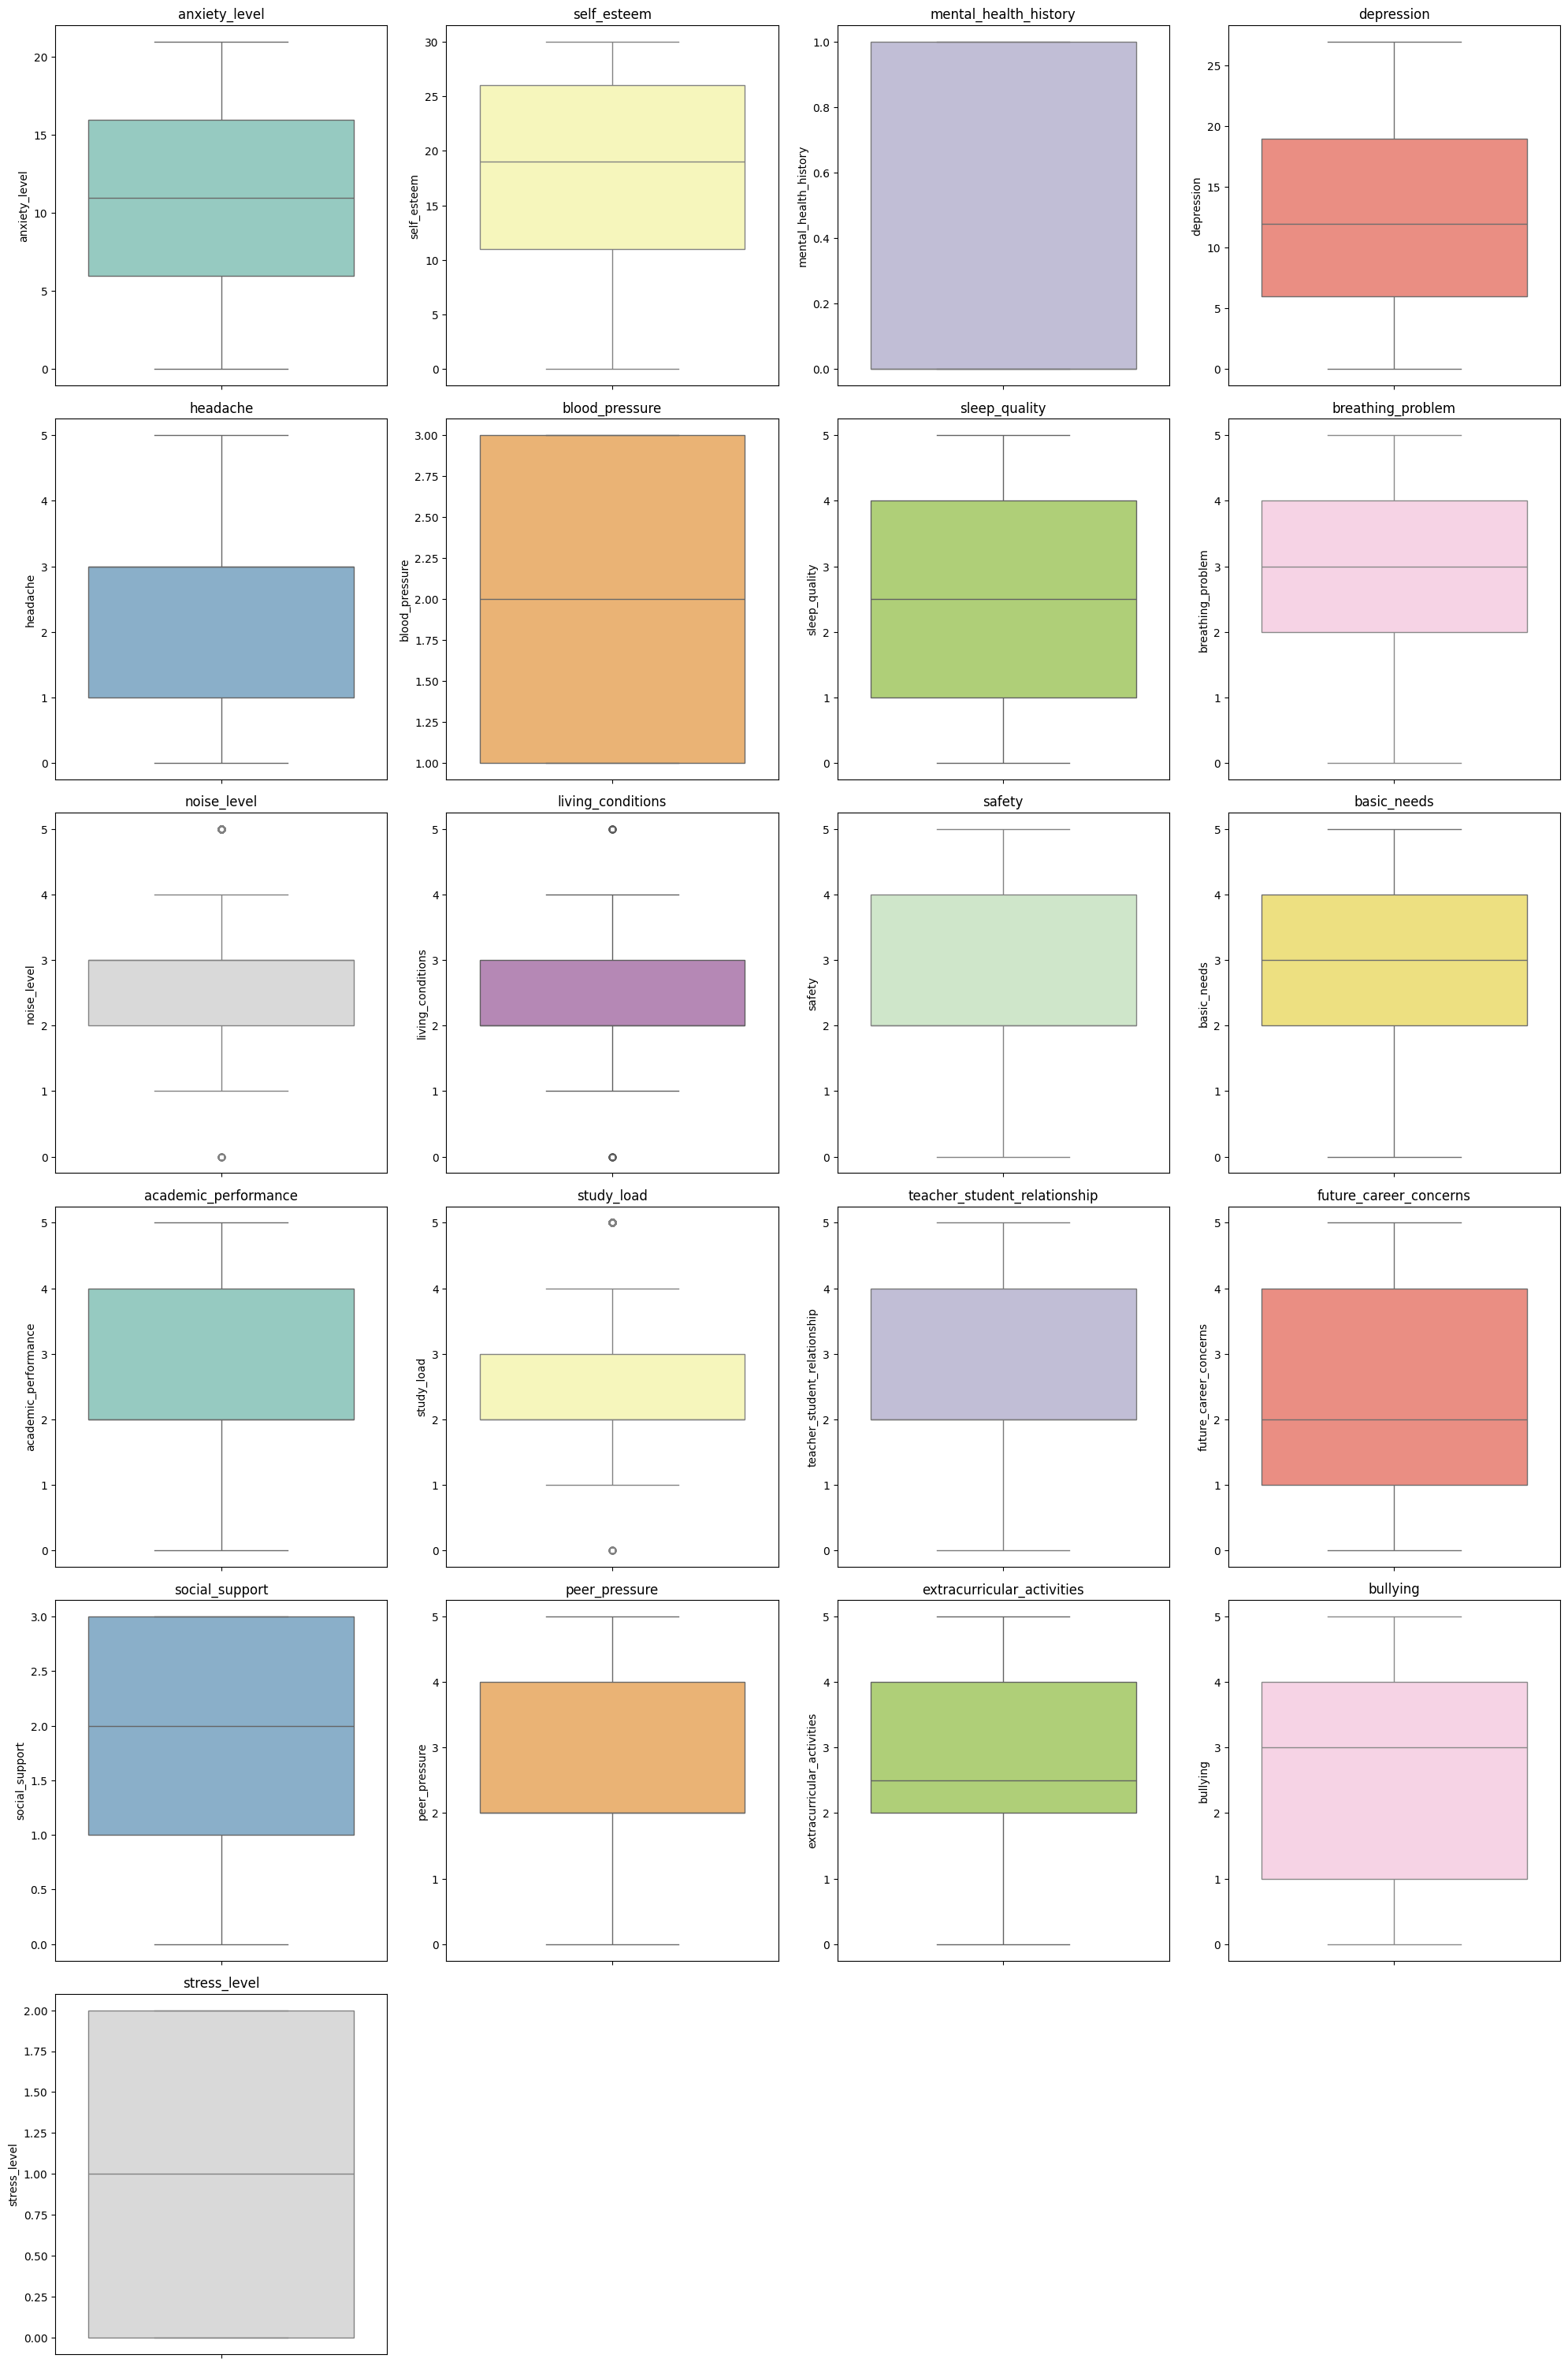

In [70]:
columns = df.columns

cols = len(columns) #Showing 4 Plots in a Row
rows = (cols + 3)

plt.figure(figsize=(20, rows * 5))

Colour = sns.color_palette("Set3", cols)

for i, col in enumerate(columns):
    plt.subplot(rows, 4, i + 1)

    sns.boxplot(y=df[col], color=Colour[i])
    plt.title(col)

plt.tight_layout()
plt.show()

### Outliers Treatment

In [71]:
def remove_outlier (col):
  sorted(col)
  Q1,Q3=col.quantile([0.25,0.75])
  IQR=Q3-Q1
  lr=Q1-(1.5*IQR)
  ur=Q3+(1.5*IQR)
  return  lr,ur

Digunakan untuk menormalkan data dengan mengganti nilai yang terlalu ekstrem (outlier) agar tidak mengganggu analisis.

In [72]:
lrnoise_level,urnoise_level=remove_outlier(df['noise_level'])
lrliving_conditions,urliving_conditions=remove_outlier(df['living_conditions'])
lrstudy_load,urstudy_load=remove_outlier(df['study_load'])


df['noise_level']=np.where(df['noise_level']<lrnoise_level,lrnoise_level,df['noise_level'])
df['noise_level']=np.where(df['noise_level']>urnoise_level,urnoise_level,df['noise_level'])


df['living_conditions']=np.where(df['living_conditions']<lrliving_conditions,lrliving_conditions,df['living_conditions'])
df['living_conditions']=np.where(df['living_conditions']>urliving_conditions,urliving_conditions,df['living_conditions'])


df['study_load']=np.where(df['study_load']<lrstudy_load,lrstudy_load,df['study_load'])
df['study_load']=np.where(df['study_load']>urstudy_load,urstudy_load,df['study_load'])

# Menerapkan Model Random Forest dan Split Data

In [73]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = df.drop("stress_level", axis=1)
y = df["stress_level"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=500,max_depth=None,min_samples_split=2,min_samples_leaf=1,class_weight="balanced",random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=500,
                       random_state=42)

In [74]:
y_train.value_counts(normalize=True)


,proportion
stress_level,
2,0.338636
0,0.337500
1,0.323864


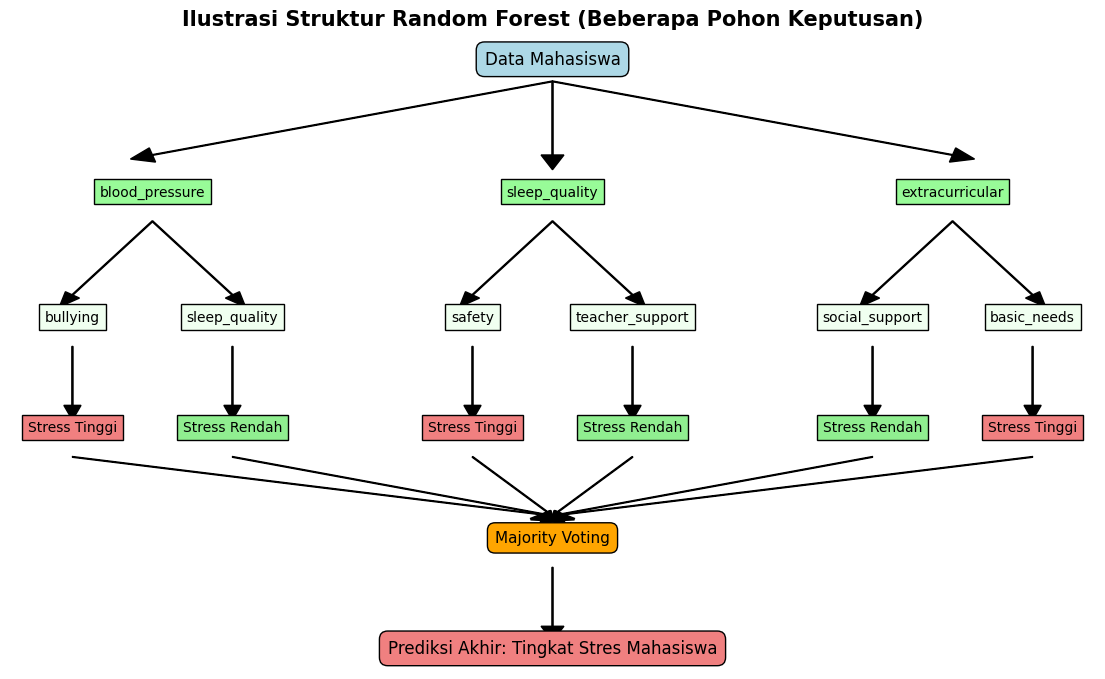

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
plt.axis('off')
plt.title('Ilustrasi Struktur Random Forest (Beberapa Pohon Keputusan)',
          fontsize=15, fontweight='bold', pad=20)

plt.text(0.5, 0.9, 'Data Mahasiswa',
         ha='center', va='center', fontsize=12,
         bbox=dict(facecolor='lightblue', edgecolor='black', boxstyle='round,pad=0.5'))

plt.text(0.15, 0.72, 'blood_pressure', ha='center', va='center',
         bbox=dict(facecolor='palegreen', edgecolor='black'))
plt.text(0.08, 0.55, 'bullying', ha='center', va='center',
         bbox=dict(facecolor='honeydew', edgecolor='black'))
plt.text(0.22, 0.55, 'sleep_quality', ha='center', va='center',
         bbox=dict(facecolor='honeydew', edgecolor='black'))
plt.text(0.08, 0.4, 'Stress Tinggi', ha='center', va='center',
         bbox=dict(facecolor='lightcoral', edgecolor='black'))
plt.text(0.22, 0.4, 'Stress Rendah', ha='center', va='center',
         bbox=dict(facecolor='lightgreen', edgecolor='black'))
plt.arrow(0.15, 0.68, -0.07, -0.1, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.15, 0.68, 0.07, -0.1, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.08, 0.51, 0, -0.08, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.22, 0.51, 0, -0.08, head_width=0.015, head_length=0.02, fc='black', ec='black')

plt.text(0.5, 0.72, 'sleep_quality', ha='center', va='center',
         bbox=dict(facecolor='palegreen', edgecolor='black'))
plt.text(0.43, 0.55, 'safety', ha='center', va='center',
         bbox=dict(facecolor='honeydew', edgecolor='black'))
plt.text(0.57, 0.55, 'teacher_support', ha='center', va='center',
         bbox=dict(facecolor='honeydew', edgecolor='black'))
plt.text(0.43, 0.4, 'Stress Tinggi', ha='center', va='center',
         bbox=dict(facecolor='lightcoral', edgecolor='black'))
plt.text(0.57, 0.4, 'Stress Rendah', ha='center', va='center',
         bbox=dict(facecolor='lightgreen', edgecolor='black'))
plt.arrow(0.5, 0.68, -0.07, -0.1, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.5, 0.68, 0.07, -0.1, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.43, 0.51, 0, -0.08, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.57, 0.51, 0, -0.08, head_width=0.015, head_length=0.02, fc='black', ec='black')

plt.text(0.85, 0.72, 'extracurricular', ha='center', va='center',
         bbox=dict(facecolor='palegreen', edgecolor='black'))
plt.text(0.78, 0.55, 'social_support', ha='center', va='center',
         bbox=dict(facecolor='honeydew', edgecolor='black'))
plt.text(0.92, 0.55, 'basic_needs', ha='center', va='center',
         bbox=dict(facecolor='honeydew', edgecolor='black'))
plt.text(0.78, 0.4, 'Stress Rendah', ha='center', va='center',
         bbox=dict(facecolor='lightgreen', edgecolor='black'))
plt.text(0.92, 0.4, 'Stress Tinggi', ha='center', va='center',
         bbox=dict(facecolor='lightcoral', edgecolor='black'))
plt.arrow(0.85, 0.68, -0.07, -0.1, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.85, 0.68, 0.07, -0.1, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.78, 0.51, 0, -0.08, head_width=0.015, head_length=0.02, fc='black', ec='black')
plt.arrow(0.92, 0.51, 0, -0.08, head_width=0.015, head_length=0.02, fc='black', ec='black')

for x in [0.15, 0.5, 0.85]:
    plt.arrow(0.5, 0.87, x - 0.5, -0.1, head_width=0.02, head_length=0.02, fc='black', ec='black')

plt.text(0.5, 0.25, 'Majority Voting', ha='center', va='center', fontsize=11,
         bbox=dict(facecolor='orange', edgecolor='black', boxstyle='round,pad=0.5'))
for x in [0.08, 0.22, 0.43, 0.57, 0.78, 0.92]:
    plt.arrow(x, 0.36, 0.5 - x, -0.08, head_width=0.015, head_length=0.02, fc='black', ec='black')

plt.text(0.5, 0.1, 'Prediksi Akhir: Tingkat Stres Mahasiswa',
         ha='center', va='center', fontsize=12,
         bbox=dict(facecolor='lightcoral', edgecolor='black', boxstyle='round,pad=0.5'))
plt.arrow(0.5, 0.21, 0, -0.08, head_width=0.02, head_length=0.02, fc='black', ec='black')

plt.show()


# Menguji Hasil Test dan Evaluasi

In [75]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8681818181818182


Classification Report
              precision    recall  f1-score   support

           0       0.87      0.86      0.86        76
           1       0.90      0.86      0.88        73
           2       0.84      0.89      0.86        71

    accuracy                           0.87       220
   macro avg       0.87      0.87      0.87       220
weighted avg       0.87      0.87      0.87       220



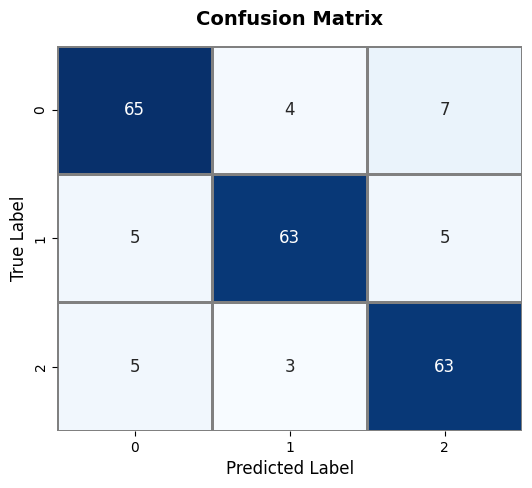

In [88]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            annot_kws={"size": 12}, linewidths=1, linecolor='gray')

plt.title("Confusion Matrix", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.show()


**Penjelasan per Metrik**

| Metrik      | Arti Singkat             | Penjelasan |
|--------------|---------------------------|-------------|
| **Precision** | Ketepatan | Dari semua prediksi positif, berapa yang benar-benar positif |
| **Recall** | Kepekaan | Dari semua data positif, berapa yang berhasil dikenali model |
| **F1-score** | Gabungan Precision & Recall | Semakin tinggi, semakin seimbang performanya |
| **Support** | Jumlah data per kelas | Berapa banyak data "kelas itu" di data uji |


**Interpretasi per Kelas**

| Kelas | Precision | Recall | F1-score | Artinya |
|--------|------------|---------|-----------|-----------|
| **0** | 0.87 | 0.86 | 0.86 | Model cukup baik mengenali kelas 0 |
| **1** | 0.90 | 0.86 | 0.88 | Paling bagus — model sangat akurat di kelas ini |
| **2** | 0.84 | 0.89 | 0.86 | Juga bagus dan seimbang |

**Rata-rata:** Precision ≈ 0.87 | Recall ≈ 0.87 | F1-score ≈ 0.87  
Model cukup stabil di semua kelas.



# Menguji Hasil Latih (Train) Model

                         Feature  Importance
5                 blood_pressure    0.146651
18    extracurricular_activities    0.084532
19                      bullying    0.070179
6                  sleep_quality    0.069081
14  teacher_student_relationship    0.067794
10                        safety    0.064659
3                     depression    0.061819
16                social_support    0.058054
11                   basic_needs    0.055947
15        future_career_concerns    0.049567
0                  anxiety_level    0.048430
1                    self_esteem    0.044894
4                       headache    0.039518
12          academic_performance    0.036561
17                 peer_pressure    0.030097
8                    noise_level    0.023780
13                    study_load    0.015733
9              living_conditions    0.015618
7              breathing_problem    0.012347
2          mental_health_history    0.004739


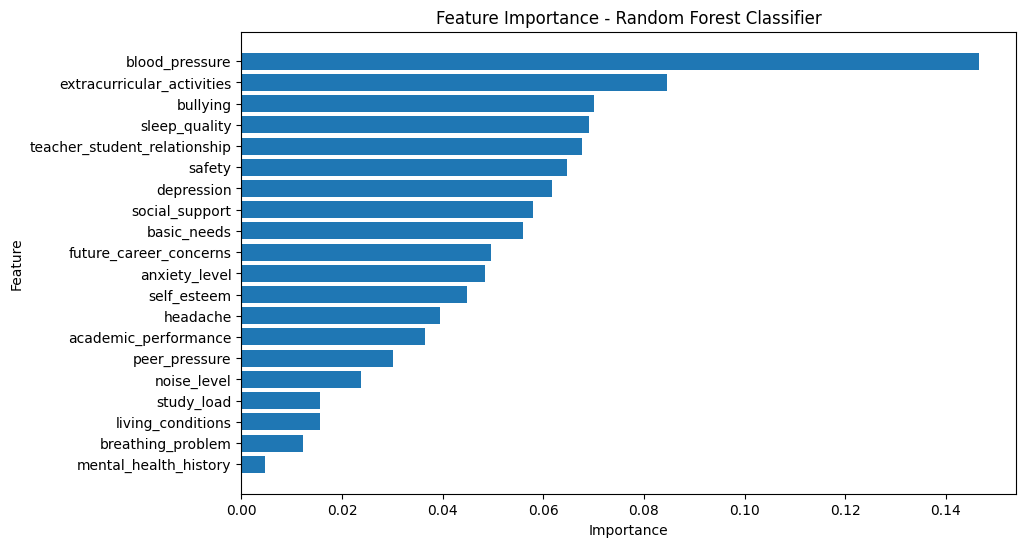

In [77]:
import pandas as pd
import matplotlib.pyplot as plt

# Ambil importance dari model
feature_importances = model.feature_importances_
1
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)
print(importance_df)

# Plot
plt.figure(figsize=(10,6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.gca().invert_yaxis()  # biar yang paling penting di atas
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance - Random Forest Classifier')
plt.show()


In [78]:
df["stress_level"].unique()

array([1, 2, 0])

# Proporsi Setiap Target (Label)

In [79]:
print(y_train.value_counts())


stress_level
2    298
0    297
1    285
Name: count, dtype: int64


# Testing Model dengan Contoh Data

In [80]:
import pandas as pd

# 🟢 Stress Level Rendah → target: 0
# Achmat, 21 tahun, hidup teratur dan percaya diri. Tidur nyenyak, tekanan darah normal, hubungan sosial baik, dan aktif berorganisasi tanpa merasa terbebani.

new_data_low = {
    "anxiety_level": 2,
    "self_esteem": 9,
    "mental_health_history": 0,
    "depression": 1,
    "headache": 0,
    "blood_pressure": 105,
    "sleep_quality": 9,
    "breathing_problem": 0,
    "noise_level": 2,
    "living_conditions": 9,
    "safety": 9,
    "basic_needs": 9,
    "academic_performance": 8,
    "study_load": 2,
    "teacher_student_relationship": 9,
    "future_career_concerns": 2,
    "social_support": 9,
    "peer_pressure": 1,
    "extracurricular_activities": 9,
    "bullying": 0
}
print("Predicted Stress Level (rendah):", model.predict(pd.DataFrame([new_data_low]))[0])


# 🟡 Stress Level Sedang → target: 1 (hasil dari pencarian acak)
# Andre, 22 tahun, mulai merasa cemas karena tugas akhir dan masa depan. Tidur kurang, tekanan darah tinggi, dan beban kuliah terasa berat meski masih bisa dikendalikan.
new_data_medium = {
    "anxiety_level": 6,
    "self_esteem": 5,
    "mental_health_history": 1,
    "depression": 8,
    "headache": 1,
    "blood_pressure": 178,
    "sleep_quality": 2,
    "breathing_problem": 8,
    "noise_level": 4,
    "living_conditions": 5,
    "safety": 3,
    "basic_needs": 4,
    "academic_performance": 4,
    "study_load": 2,
    "teacher_student_relationship": 2,
    "future_career_concerns": 6,
    "social_support": 8,
    "peer_pressure": 1,
    "extracurricular_activities": 1,
    "bullying": 0
}
print("Predicted Stress Level (sedang):", model.predict(pd.DataFrame([new_data_medium]))[0])


# 🔴 Stress Level Tinggi → target: 2
# Azka, 20 tahun, sering cemas, sulit tidur, tekanan darah tinggi, dan lingkungan tidak mendukung. Nilai turun, hubungan sosial buruk, serta merasa tertekan dan lelah.
new_data_high = {
    "anxiety_level": 9,
    "self_esteem": 1,
    "mental_health_history": 1,
    "depression": 9,
    "headache": 8,
    "blood_pressure": 170,
    "sleep_quality": 1,
    "breathing_problem": 6,
    "noise_level": 9,
    "living_conditions": 2,
    "safety": 2,
    "basic_needs": 3,
    "academic_performance": 3,
    "study_load": 9,
    "teacher_student_relationship": 2,
    "future_career_concerns": 9,
    "social_support": 2,
    "peer_pressure": 8,
    "extracurricular_activities": 1,
    "bullying": 8
}
print("Predicted Stress Level (tinggi):", model.predict(pd.DataFrame([new_data_high]))[0])


Predicted Stress Level (rendah): 0
Predicted Stress Level (sedang): 1
Predicted Stress Level (tinggi): 2


In [81]:
import joblib

# Simpan model ke file .pkl
joblib.dump(model, "model_stress.pkl")

print("Model berhasil disimpan ke 'model_stress.pkl'")

✅ Model berhasil disimpan ke 'model_stress.pkl'
